# Steam games — EDA and initial KNN assessment

**Purpose:** inspect the processed dataset and assess the default KNN before tuning. Load `data/games.parquet`, exported by `mle-process-data.ipynb`. Run that preprocessing notebook first if the file is missing.

Ownership columns, target labels, game age and genre/tag indicators are already stored in the Parquet. This notebook reads and checks them without cleaning the CSV, rebuilding features or reassigning labels.

- **Estimated owners (lb):** lower endpoint of the source interval.
- **Estimated owners (ub):** upper endpoint.
- **Estimated owners (mid):** `(lower bound + upper bound) / 2`.

For `20000 - 50000`, the stored values should be **20,000**, **50,000**, and **35,000**. These describe the outcome and are excluded from model inputs. All checks below are self-contained.

## 1. Dataset overview

Inspect the processed Parquet dataset. Shapes and example rows appear below; the additional overview includes data types, release-date coverage and duplicate checks that support nested list columns.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, balanced_accuracy_score, f1_score,
                             mean_absolute_error, mean_squared_error)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "games.parquet").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/games.parquet. Run mle-process-data.ipynb first.")
PATH = ROOT / "data" / "games.parquet"
df = pd.read_parquet(PATH)
assert not df.empty, "Processed dataset is empty."
assert df.columns.is_unique, "Processed dataset contains duplicate column names."
assert "steam_appid" in df.columns, "Processed dataset is missing steam_appid."
assert df["steam_appid"].notna().all() and df["steam_appid"].is_unique

OWNER_LB = "Estimated owners (lb)"
OWNER_UB = "Estimated owners (ub)"
OWNER_MID = "Estimated owners (mid)"
OWNER_COLUMNS = [OWNER_LB, OWNER_UB, OWNER_MID]
print(f"Loaded {PATH.name}: {len(df):,} games; {len(df.columns):,} columns")
display(df.head(3))

Loaded games.parquet: 58,614 games; 526 columns


,steam_appid,Name,Release date,Estimated owners,Peak CCU,Required age,Price,DLC count,About the game,Supported languages,...,genre_Simulation,genre_Software Training,genre_Sports,genre_Strategy,genre_Tutorial,genre_Utilities,genre_Video Production,genre_Violent,genre_Web Publishing,target
0,10,Counter-Strike,2000-11-01,10000000 - 20000000,13230,0,9.99,0,Play the world's number 1 online action game. ...,"['English', 'French', 'German', 'Italian', 'Sp...",...,0,0,0,0,0,0,0,0,0,2
1,20,Team Fortress Classic,1999-04-01,5000000 - 10000000,110,0,4.99,0,One of the most popular online action games of...,"['English', 'French', 'German', 'Italian', 'Sp...",...,0,0,0,0,0,0,0,0,0,2
2,30,Day of Defeat,2003-05-01,5000000 - 10000000,106,0,4.99,0,Enlist in an intense brand of Axis vs. Allied ...,"['English', 'French', 'German', 'Italian', 'Sp...",...,0,0,0,0,0,0,0,0,0,2


In [ ]:
print("Dataset shape (rows, columns):", df.shape)
display(df.dtypes.astype(str).rename("dtype").rename_axis("column").to_frame())
display(df.dtypes.astype(str).value_counts().rename("columns").to_frame())
print("Release-date coverage:", df["Release date"].min(), "to", df["Release date"].max())
print("Duplicate game IDs:", int(df["steam_appid"].duplicated().sum()))

# Make nested values hashable in a temporary view; leave df unchanged.
def duplicate_key(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return tuple(duplicate_key(item) for item in value)
    if isinstance(value, dict):
        return tuple(sorted((key, duplicate_key(item)) for key, item in value.items()))
    return value

duplicate_view = df.copy(deep=False)
for column in df.select_dtypes(include=["object"]).columns:
    duplicate_view[column] = df[column].map(duplicate_key)
print("Duplicate complete rows:", int(duplicate_view.duplicated().sum()))
del duplicate_view

,dtype
column,
steam_appid,int64
Name,str
Release date,object
Estimated owners,str
Peak CCU,int64
...,...
genre_Utilities,int64
genre_Video Production,int64
genre_Violent,int64


,columns
int64,496
str,15
object,6
float64,6
bool,3


Dataset shape (rows, columns): (58614, 526)
Release-date coverage: 1997-06-30 to 2022-07-05
Duplicate game IDs: 0
Duplicate complete rows: 0


## 2. Target analysis

### Ownership definitions and stored-label audit

The preprocessing notebook already created the ownership columns and target. Check lower ≤ midpoint ≤ upper, midpoint = `(lb + ub) / 2`, and the explicit class mapping: 0 = <20k; 1 = 20k–<100k; 2 = 100k+.

A failed check should be resolved in `mle-process-data.ipynb` and followed by regenerating `games.parquet`; this assessment does not silently repair the exported data.

In [2]:
required = ["target", *OWNER_COLUMNS]
assert all(col in df.columns for col in required), "Missing target-related columns; regenerate games.parquet."
assert np.isfinite(df[OWNER_COLUMNS].to_numpy(dtype=float)).all(), "Invalid stored ownership values."
assert (df[OWNER_LB] >= 0).all()
assert (df[OWNER_LB] <= df[OWNER_MID]).all() and (df[OWNER_MID] <= df[OWNER_UB]).all()
assert np.allclose(df[OWNER_MID], (df[OWNER_LB] + df[OWNER_UB]) / 2)
for edge in [20_000, 100_000]:
    assert not ((df[OWNER_LB] < edge) & (df[OWNER_UB] > edge)).any(), f"Ownership interval crosses {edge}."
expected_target = np.select([df[OWNER_LB] < 20_000, df[OWNER_LB] < 100_000], [0, 1], default=2)
assert df["target"].notna().all() and set(df["target"]) == {0, 1, 2}
assert np.array_equal(df["target"].to_numpy(), expected_target), "Stored target mapping is incorrect; regenerate games.parquet."

label_audit = (df.groupby(["target", OWNER_LB, OWNER_UB], dropna=False)
                 .size().reset_index(name="games")
                 .sort_values(["target", OWNER_LB]))
display(label_audit.to_string(index=False))
print("Target class counts:")
display(df["target"].value_counts().sort_index().rename("games").to_frame())
print("Stored ownership columns and target mapping verified.")

' target  Estimated owners (lb)  Estimated owners (ub)  games\n      0                    0.0                20000.0  41595\n      1                20000.0                50000.0   7120\n      1                50000.0               100000.0   3552\n      2               100000.0               200000.0   2397\n      2               200000.0               500000.0   2074\n      2               500000.0              1000000.0    884\n      2              1000000.0              2000000.0    516\n      2              2000000.0              5000000.0    325\n      2              5000000.0             10000000.0     87\n      2             10000000.0             20000000.0     38\n      2             20000000.0             50000000.0     21\n      2             50000000.0            100000000.0      4\n      2            100000000.0            200000000.0      1'

Target class counts:


,games
target,
0,41595
1,10672
2,6347


Stored ownership columns and target mapping verified.


In [3]:
source_ranges = df[["Estimated owners", *OWNER_COLUMNS]].drop_duplicates().sort_values(OWNER_LB)
display(source_ranges)

,Estimated owners,Estimated owners (lb),Estimated owners (ub),Estimated owners (mid)
26,0 - 20000,0.0,20000.0,10000.0
28,20000 - 50000,20000.0,50000.0,35000.0
33,50000 - 100000,50000.0,100000.0,75000.0
31,100000 - 200000,100000.0,200000.0,150000.0
44,200000 - 500000,200000.0,500000.0,350000.0
29,500000 - 1000000,500000.0,1000000.0,750000.0
45,1000000 - 2000000,1000000.0,2000000.0,1500000.0
12,2000000 - 5000000,2000000.0,5000000.0,3500000.0
1,5000000 - 10000000,5000000.0,10000000.0,7500000.0
0,10000000 - 20000000,10000000.0,20000000.0,15000000.0


,games,share_pct
Owner band,,
<20k,41595,70.96
20k–<100k,10672,18.21
100k+,6347,10.83


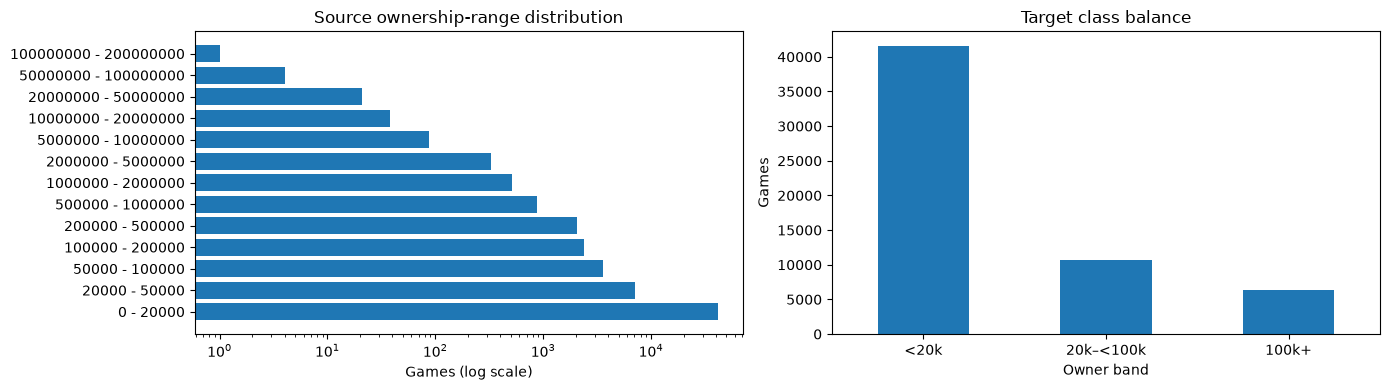

In [ ]:
range_counts = df.groupby(OWNER_LB, sort=True).agg(
    games=("target", "size"), ownership_range=("Estimated owners", "first"))
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].barh(range_counts["ownership_range"], range_counts["games"])
axs[0].set(xlabel="Games (log scale)", title="Source ownership-range distribution", xscale="log")
class_balance = df["target"].value_counts().sort_index().rename("games").to_frame()
class_balance["share_pct"] = 100 * class_balance["games"] / len(df)
class_balance.index = pd.Index(["<20k", "20k–<100k", "100k+"], name="Owner band")
display(class_balance.round(2))
class_balance["games"].plot.bar(ax=axs[1], rot=0)
axs[1].set(xlabel="Owner band", ylabel="Games", title="Target class balance")
plt.tight_layout(); plt.show()

## 3. Data quality

All statistics refer to the processed dataset. Missing-value counts below are followed by invalid-value and outlier checks. These checks report findings without changing or removing records.

In [4]:
missing = pd.DataFrame({"missing_n": df.isna().sum(), "missing_pct": 100 * df.isna().mean()})
display(missing.sort_values("missing_pct", ascending=False).head(25))

,missing_n,missing_pct
Steam score,4239,7.232061
tag_Relaxing,0,0.000000
tag_Reboot,0,0.000000
tag_Realistic,0,0.000000
tag_Real-Time with Pause,0,0.000000
tag_Real-Time,0,0.000000
tag_Real Time Tactics,0,0.000000
tag_Racing,0,0.000000
tag_RTS,0,0.000000
tag_RPGMaker,0,0.000000


In [ ]:
numeric_columns = ["Price", "Required age", "Achievements", "year", "Positive", "Negative", "Peak CCU", "DLC count"]
quality_rows = []
for column in numeric_columns:
    if column not in df:
        continue
    original = df[column]
    values = pd.to_numeric(original, errors="coerce")
    finite = values[np.isfinite(values)]
    q1, q3 = finite.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = ((finite < q1 - 1.5 * iqr) | (finite > q3 + 1.5 * iqr)).sum()
    quality_rows.append({"feature": column, "missing": int(original.isna().sum()),
        "non_numeric": int((original.notna() & values.isna()).sum()),
        "infinite": int(np.isinf(values).sum()), "negative": int((values < 0).sum()),
        "iqr_outliers": int(flagged), "iqr_outlier_pct": 100 * flagged / len(finite) if len(finite) else np.nan})
display(pd.DataFrame(quality_rows).set_index("feature").round(2))
indicator_columns = [col for col in df if col.startswith(("genre_", "tag_"))] + ["Windows", "Mac", "Linux"]
invalid_indicators = pd.Series({col: int((df[col].notna() & ~df[col].isin([0, 1])).sum())
    for col in indicator_columns if col in df}, name="invalid_binary_values")
print("Invalid binary indicator values:", int(invalid_indicators.sum()))
display(invalid_indicators[invalid_indicators > 0].to_frame())
release_dates = pd.to_datetime(df["Release date"], errors="coerce")
print("Missing or unparseable release dates:", int(release_dates.isna().sum()))
print("Releases after eligibility cutoff (2022-07-05):", int((release_dates > pd.Timestamp("2022-07-05")).sum()))
print("IQR flags are inspection candidates, not invalid records. Zero-heavy features can have IQR = 0; do not remove games automatically.")

,missing,non_numeric,infinite,negative,iqr_outliers,iqr_outlier_pct
feature,,,,,,
Price,0,0,0,0,2859,4.88
Required age,0,0,0,0,1391,2.37
Achievements,0,0,0,0,3840,6.55
year,0,0,0,0,1476,2.52
Positive,0,0,0,0,9867,16.83
Negative,0,0,0,0,9200,15.70
Peak CCU,0,0,0,0,9354,15.96
DLC count,0,0,0,0,9707,16.56


,invalid_binary_values


Invalid binary indicator values: 0
Missing or unparseable release dates: 0
Releases after eligibility cutoff (2022-07-05): 0
IQR flags are inspection candidates, not invalid records. Zero-heavy features can have IQR = 0; do not remove games automatically.


## 4. Univariate analysis

Inspect individual numerical distributions and categorical prevalence. Review and concurrency statistics are descriptive only; they are excluded from baseline predictors.

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
Price,58614.0,7.545333,11.142590,0.0,0.000000,0.990000,4.990000,9.990000,19.990000,39.990000,9.990000e+02
Required age,58614.0,0.384720,2.494142,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,2.100000e+01
Achievements,58614.0,24.892637,206.043081,0.0,0.000000,0.000000,5.000000,20.000000,59.000000,121.000000,9.821000e+03
year,58614.0,4.426098,2.635929,1.0,1.057534,2.375342,3.980822,5.816438,9.002877,13.884575,2.603014e+01
Positive,58614.0,1365.718224,29333.163262,0.0,0.000000,3.000000,16.000000,92.000000,2177.050000,19815.480000,5.764420e+06
Negative,58614.0,224.773945,5504.353006,0.0,0.000000,1.000000,5.000000,28.000000,414.000000,3222.610000,8.959780e+05
Peak CCU,58614.0,114.624390,4822.935044,0.0,0.000000,0.000000,0.000000,1.000000,37.000000,738.740000,8.252150e+05
DLC count,58614.0,0.706623,16.488163,0.0,0.000000,0.000000,0.000000,0.000000,2.000000,8.000000,2.366000e+03


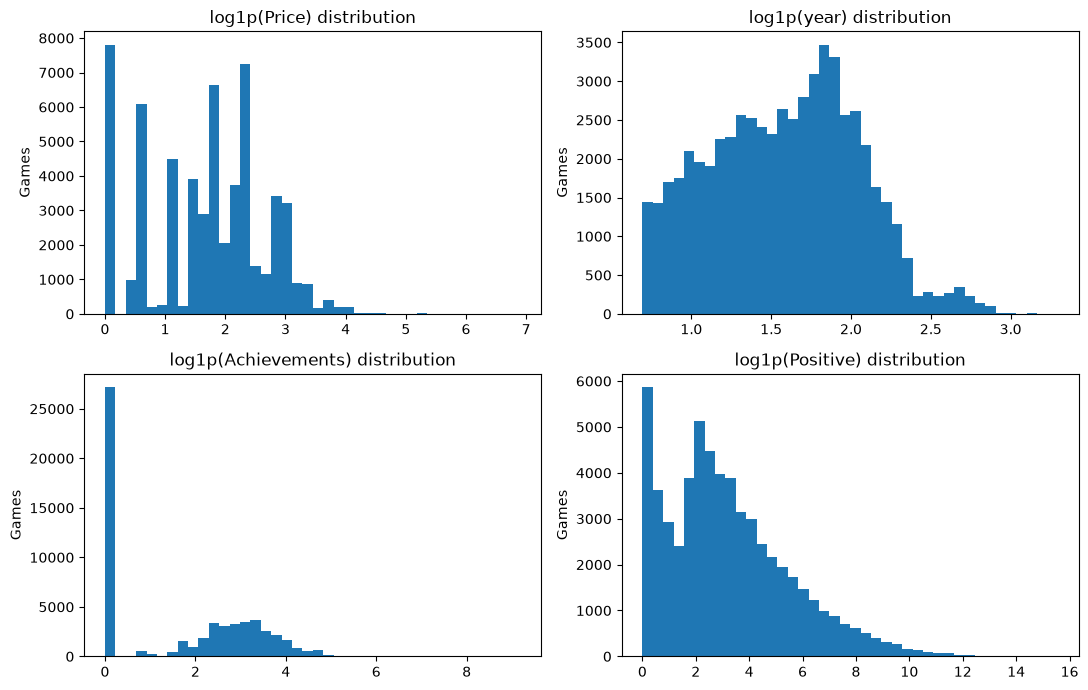

In [5]:
core = ["Price", "Required age", "Achievements", "year", "Positive", "Negative", "Peak CCU", "DLC count"]
core = [col for col in core if col in df.columns]
display(df[core].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
fig, axs = plt.subplots(2, 2, figsize=(11,7))
for ax, column in zip(axs.flat, ["Price", "year", "Achievements", "Positive"]):
    if column in df:
        values = pd.to_numeric(df[column], errors="coerce").dropna().clip(lower=0)
        ax.hist(np.log1p(values), bins=40)
        ax.set_title(f"log1p({column}) distribution")
for ax in axs.flat: ax.set_ylabel("Games")
plt.tight_layout(); plt.show()

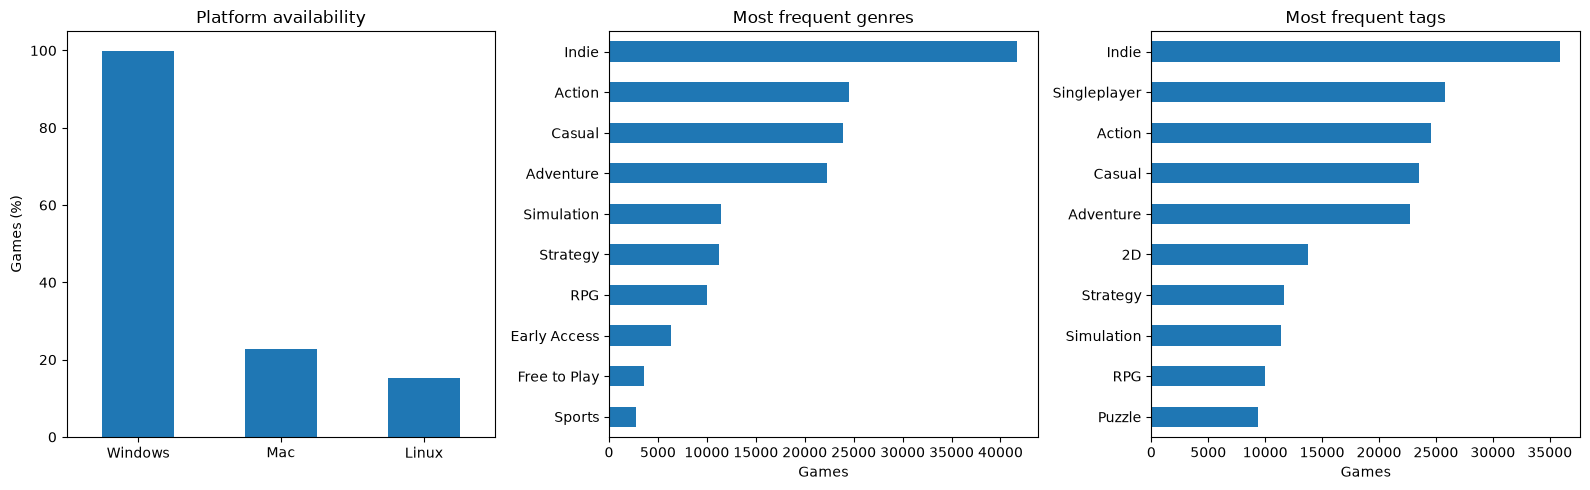

Genres and tags are multi-label: their counts do not sum to the number of games.


In [ ]:
# Numeric distributions are shown above; inspect categorical prevalence visually.
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
platforms = [col for col in ["Windows", "Mac", "Linux"] if col in df]
df[platforms].mean().mul(100).plot.bar(ax=axs[0], rot=0)
axs[0].set(title="Platform availability", ylabel="Games (%)")
for ax, prefix, title in zip(axs[1:], ["genre_", "tag_"], ["Most frequent genres", "Most frequent tags"]):
    columns = [col for col in df if col.startswith(prefix)]
    counts = df[columns].sum().nlargest(10).sort_values()
    counts.index = counts.index.str.removeprefix(prefix)
    counts.plot.barh(ax=ax)
    ax.set(title=title, xlabel="Games")
plt.tight_layout(); plt.show()
print("Genres and tags are multi-label: their counts do not sum to the number of games.")

## 5. Bivariate analysis

Compare numerical predictors across ownership classes, then examine owner-band composition for frequent genres/tags and platform availability. Popularity outcomes shown for context are excluded from training.

In [6]:
# Inspect trends across ownership classes without using them as model features here.
for col in ["Price", "year", "Achievements", "Positive", "Peak CCU"]:
    if col in df:
        print(f"\n{col} by target class:")
        display(df.groupby("target")[col].agg(["count", "median", "mean"]).round(2))

binary_cols = [col for col in ["Windows", "Mac", "Linux"] if col in df]
if binary_cols:
    display(df[binary_cols].mean(numeric_only=True).rename("fraction_true").to_frame())

for prefix in ["genre_", "tag_"]:
    cols = [col for col in df if col.startswith(prefix)]
    print(f"{prefix}: {len(cols)} columns")
    if cols:
        display(df[cols].sum().sort_values(ascending=False).head(15).rename("games").to_frame())


Price by target class:


,count,median,mean
target,,,
0,41595,4.99,7.03
1,10672,4.99,7.43
2,6347,7.99,11.15



year by target class:


,count,median,mean
target,,,
0,41595,3.54,3.82
1,10672,5.14,5.34
2,6347,6.64,6.84



Achievements by target class:


,count,median,mean
target,,,
0,41595,1.0,20.64
1,10672,9.0,30.90
2,6347,19.0,42.68


... (5 outputs left out)

genre_: 33 columns


,games
genre_Indie,41711
genre_Action,24559
genre_Casual,23957
genre_Adventure,22287
genre_Simulation,11437
genre_Strategy,11202
genre_RPG,10016
genre_Early Access,6364
genre_Free to Play,3528
genre_Sports,2748


tag_: 448 columns


,games
tag_Indie,35866
tag_Singleplayer,25807
tag_Action,24535
tag_Casual,23526
tag_Adventure,22691
tag_2D,13721
tag_Strategy,11625
tag_Simulation,11374
tag_RPG,9943
tag_Puzzle,9390


,games,<20k,20k–<100k,100k+
feature,,,,
genre_Indie,41711,0.734,0.178,0.088
genre_Action,24559,0.698,0.176,0.126
genre_Casual,23957,0.781,0.158,0.062
genre_Adventure,22287,0.700,0.193,0.108
genre_Simulation,11437,0.710,0.176,0.115
genre_Strategy,11202,0.649,0.207,0.143
genre_RPG,10016,0.627,0.223,0.150
genre_Early Access,6364,0.787,0.144,0.069
genre_Free to Play,3528,0.331,0.371,0.298


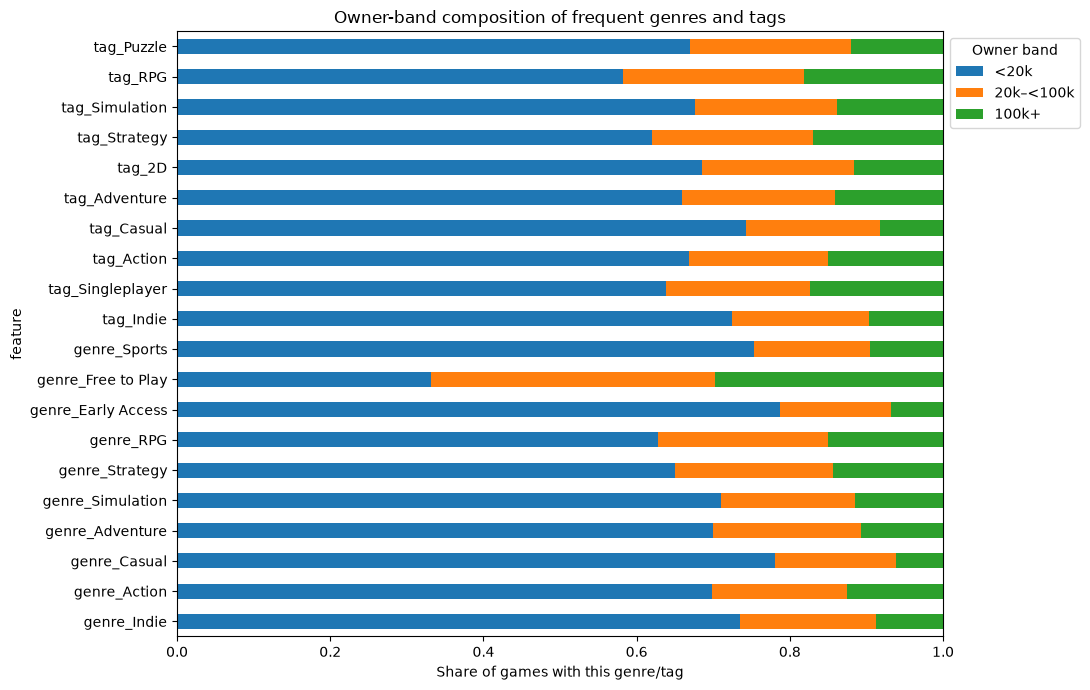

games   <20k  20k–<100k  100k+
platform available                                
Windows  False         25  0.800      0.200  0.000
         True       58589  0.710      0.182  0.108
Mac      False      45248  0.741      0.169  0.090
         True       13366  0.602      0.228  0.170
Linux    False      49724  0.730      0.174  0.096
         True        8890  0.599      0.226  0.176

Compare conditional proportions with the overall class balance. Multi-label groups overlap; differences are descriptive associations, not causal effects.


In [ ]:
# Conditional class proportions add categorical/predictor relationships.
owner_labels = {0: "<20k", 1: "20k–<100k", 2: "100k+"}
rows = []
for prefix in ["genre_", "tag_"]:
    columns = [col for col in df if col.startswith(prefix)]
    frequent = df[columns].sum().nlargest(10).index
    for column in frequent:
        selected = df[column].eq(1)
        counts = df.loc[selected, "target"].value_counts().reindex([0, 1, 2], fill_value=0)
        rows.append({"feature": column, "games": int(selected.sum()),
            **{owner_labels[k]: counts[k] / selected.sum() if selected.any() else np.nan for k in owner_labels}})
categorical_target = pd.DataFrame(rows).set_index("feature")
display(categorical_target.round(3))
fig, ax = plt.subplots(figsize=(11, 7))
categorical_target[list(owner_labels.values())].plot.barh(stacked=True, ax=ax)
ax.set(xlabel="Share of games with this genre/tag", title="Owner-band composition of frequent genres and tags", xlim=(0, 1))
ax.legend(title="Owner band", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
platform_rows = []
for column in ["Windows", "Mac", "Linux"]:
    if column in df:
        for present in [0, 1]:
            subset = df.loc[df[column].eq(present), "target"]
            counts = subset.value_counts().reindex([0, 1, 2], fill_value=0)
            platform_rows.append({"platform": column, "available": bool(present), "games": len(subset),
                **{owner_labels[k]: counts[k] / len(subset) if len(subset) else np.nan for k in owner_labels}})
display(pd.DataFrame(platform_rows).set_index(["platform", "available"]).round(3))
print("Compare conditional proportions with the overall class balance. Multi-label groups overlap; differences are descriptive associations, not causal effects.")

## 6. EDA conclusions

- **Imbalance shapes the task:** 70.96% of games fall below 20k owners, while only 10.83% reach 100k+. Assess macro F1, balanced accuracy and high-owner precision/recall alongside accuracy.
- **Ownership is an interval-valued outcome:** lower/upper bounds and midpoint are verified, and all ownership-derived fields remain outside model inputs. Predictions describe cumulative estimated-owner bands.
- **Distance needs careful treatment:** price and achievement counts are right-skewed, with large extremes, while platform, genre and tag features are binary. An unscaled KNN can give disproportionate weight to numeric differences; test scaling and suitable transformations inside cross-validation folds. IQR flags alone do not justify deleting observations.
- **Predictors have different coverage and meaning:** Windows is nearly universal, whereas Mac/Linux and individual tags cover smaller groups. Genres/tags overlap. Conditional owner-band proportions and age/price summaries suggest candidate signals, but do not establish causality or out-of-sample value.
- **Added quality checks passed:** there are no duplicate IDs or complete rows, no negative/non-numeric/infinite values in the inspected numeric features, no invalid binary indicators, and no missing or ineligible release dates. The IQR rule flags 4.88% of prices and 6.55% of achievement counts for review; these are not automatically data errors.
- **Missingness is feature-specific:** the baseline inputs contain no missing values; missing Steam scores do not affect this KNN. Preserve missing-value handling within training pipelines for later experiments and inference.
- **Scope limits generalization:** the dataset excludes games less than one year old at the July 2023 snapshot. Age is associated with accumulated ownership, and present-day metadata may differ from release-time metadata. Random splits cannot establish performance for future launches.

The model assessment below quantifies these implications using the existing baseline, majority benchmark and five-fold cross-validation. The final assessment retains the previously recorded results and recommendations.

## 7. Assess the original untuned KNN configuration

Use the stored numeric/tag/genre features, an 80/20 random split with `random_state=42`, and default `KNeighborsClassifier()`. No scaling, tuning or feature reconstruction is added. Ownership columns and target bands are checked before training. The baseline uses the original preprocessing notebook's full-dataset genre/tag encoding for reference; improved experiments fit learned preprocessing within training folds.

In [7]:
DEFAULT_FEATURES = ["Price", "Required age", "Windows", "Mac", "Linux", "Achievements", "year"]
X_cols = DEFAULT_FEATURES + [col for col in df.columns
    if (col.startswith("genre_") and col != "genre_Free to Play")
    or (col.startswith("tag_") and col != "tag_Free to Play")]
missing_features = [col for col in X_cols if col not in df.columns]
assert not missing_features, f"Missing features: {missing_features}"
X = df[X_cols].apply(pd.to_numeric, errors="coerce")
y = df["target"].astype(int)
print(f"Baseline feature count: {len(X_cols)}")
print(f"NaN feature values: {int(X.isna().sum().sum())}")
assert X.notna().all().all(), "Existing KNN cannot handle missing data; fix/record missing handling first."
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
pred_train = knn.predict(X_train)
pred_test = knn.predict(X_test)

Baseline feature count: 486
NaN feature values: 0


,accuracy,balanced_accuracy,macro_F1,weighted_F1,ordinal_MAE,ordinal_RMSE,within_one_class
split,,,,,,,
train,0.7781,0.5137,0.5629,0.7359,0.2841,0.6391,0.9378
test,0.7356,0.4434,0.4672,0.6796,0.3291,0.6772,0.9353


TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.76      0.97      0.85      8308
           1       0.40      0.15      0.22      2172
           2       0.75      0.21      0.33      1243

    accuracy                           0.74     11723
   macro avg       0.64      0.44      0.47     11723
weighted avg       0.69      0.74      0.68     11723



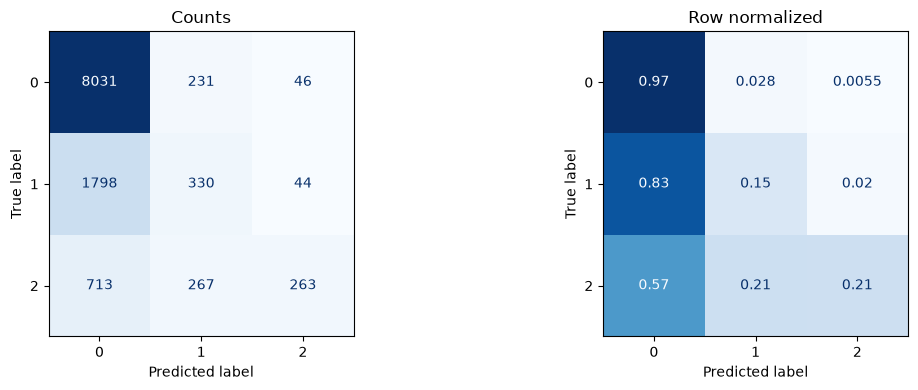

In [8]:
def report_split(name, truth, pred):
    result = {
        "split": name,
        "accuracy": accuracy_score(truth, pred),
        "balanced_accuracy": balanced_accuracy_score(truth, pred),
        "macro_F1": f1_score(truth, pred, average="macro", zero_division=0),
        "weighted_F1": f1_score(truth, pred, average="weighted", zero_division=0),
        "ordinal_MAE": mean_absolute_error(truth, pred),
        "ordinal_RMSE": np.sqrt(mean_squared_error(truth, pred)),
        "within_one_class": np.mean(np.abs(np.asarray(truth) - np.asarray(pred)) <= 1),
    }
    return result
results = pd.DataFrame([report_split("train", y_train, pred_train),
                        report_split("test", y_test, pred_test)]).set_index("split")
display(results.round(4))
print("TEST CLASSIFICATION REPORT")
print(classification_report(y_test, pred_test, labels=sorted(y.unique()), zero_division=0))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, normalize, title in zip(axs, [None, "true"], ["Counts", "Row normalized"]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test,
        labels=sorted(y.unique()), normalize=normalize, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 8. Simple majority-class benchmark
The baseline should beat a trivial model that always predicts the most common training class. Use this as an additional reference point.

In [9]:
majority_class = y_train.value_counts().idxmax()
majority_pred = np.repeat(majority_class, len(y_test))
comparison = pd.DataFrame([report_split("majority (test)", y_test, majority_pred),
                           report_split("original KNN (test)", y_test, pred_test)]).set_index("split")
display(comparison.round(4))

,accuracy,balanced_accuracy,macro_F1,weighted_F1,ordinal_MAE,ordinal_RMSE,within_one_class
split,,,,,,,
majority (test),0.7087,0.3333,0.2765,0.5879,0.3973,0.7806,0.8940
original KNN (test),0.7356,0.4434,0.4672,0.6796,0.3291,0.6772,0.9353


## 9. Optional robustness check: cross-validation on training data only
This does **not** tune the model or select features; it estimates the stability of the untuned KNN. Leave the held-out test set aside. Ownership bounds, midpoint and ordinal labels have been verified above.

In [10]:
min_class_count = y_train.value_counts().min()
folds = 5
assert min_class_count >= folds, "At least five training examples per class are required."
if folds >= 2:
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
    scores = cross_validate(KNeighborsClassifier(), X_train, y_train, cv=cv,
        scoring={"macro_f1": "f1_macro", "balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"},
        n_jobs=-1, error_score="raise")
    display(pd.DataFrame({k.replace("test_", ""): v for k, v in scores.items() if k.startswith("test_")}).describe().loc[["mean", "std"]])
else:
    print("Insufficient examples in the rarest training class for stratified CV.")

,macro_f1,balanced_accuracy,accuracy
mean,0.454922,0.434550,0.734704
std,0.002724,0.001861,0.001431


## 10. Assessment notes

The untuned KNN provides a useful reference, but its strong preference for the lowest owner band limits its value for identifying popular games. The following assessment uses the saved results above; source-row counts and release-date bounds were also checked directly against the project data.

**Coverage and data quality.** The processed dataset contains **58,614 games**, retaining **68.87%** of the 85,103 source records. Releases range from **30 June 1997 to 5 July 2022**. Preprocessing keeps games at least one calendar year old at the **5 July 2023** observation date and with a positive ownership midpoint. The `year` feature is game age, with a median of 3.98 years. These results therefore describe established games, and do not establish performance for new releases or excluded records. Game IDs are unique; the added dataset-overview check found no complete-row duplicates using hashable representations of list-valued columns. `Steam score` has 4,239 missing values (7.23%), but is excluded from the baseline. All **486 selected model features** have no missing values.

**Ownership definitions and target correctness.** The stored lower bound and upper bound match the source ownership intervals, and the midpoint is `(lb + ub) / 2`. The audit passed for finite values, ordered bounds, midpoint consistency, threshold crossings and target mapping: **0 = <20k**, **1 = 20k–<100k**, **2 = 100k+**, assigned using the lower bound of each source interval. These are estimated cumulative-owner bands, rather than measured downloads or forecasts over a fixed future period. Ownership columns and the target are excluded from model inputs.

**Class imbalance and exploratory findings.** Class 0 contains **41,595 games (70.96%)**, class 1 contains **10,672 (18.21%)**, and class 2 contains **6,347 (10.83%)**. Accuracy alone therefore rewards predicting the lowest band. Higher-owner games are generally older (median ages 3.54, 5.14 and 6.64 years across classes), and have more achievements (medians 1, 9 and 19). Median price is 4.99 for the first two classes and 7.99 for the highest. These are associations, not evidence that changing a game's price or achievements increases ownership. Price and achievement counts have substantial outliers, which can distort unscaled distance calculations. Review counts and peak concurrent users also rise with ownership, but are popularity outcomes and are excluded from this baseline.

**Held-out performance versus a trivial predictor.** The 80/20 random split yields **46,891 training games** and **11,723 test games**.

| Test metric | Majority-class predictor | Default KNN |
| --- | ---: | ---: |
| Accuracy | 0.7087 | 0.7356 |
| Balanced accuracy | 0.3333 | 0.4434 |
| Macro F1 | 0.2765 | 0.4672 |
| Weighted F1 | 0.5879 | 0.6796 |
| Ordinal MAE | 0.3973 | 0.3291 |
| Ordinal RMSE | 0.7806 | 0.6772 |

KNN improves accuracy by **2.69 percentage points**, macro F1 by **0.1907**, and balanced accuracy by **0.1101**. It learns useful information beyond the majority benchmark, although its balanced accuracy remains low.

**Performance by owner category.** Rows of the confusion matrix represent actual classes; columns represent predicted classes.

| Actual owner band | Test games | Correct predictions | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: | ---: |
| <20k | 8,308 | 8,031 | 0.76 | 0.97 | 0.85 |
| 20k–<100k | 2,172 | 330 | 0.40 | 0.15 | 0.22 |
| 100k+ | 1,243 | 263 | 0.75 | 0.21 | 0.33 |

The most common error is assigning **1,798 medium-owner games to the lowest band**. For the business-priority **100k+** band, KNN correctly identifies only **263 of 1,243 games**, missing **980 (78.84%)**: 713 are predicted below 20k and 267 in the middle band. Of the 353 high-owner predictions, 90 are false positives. High-owner precision is relatively strong, but low recall means many potential partnership opportunities would be missed. Overall, **93.53%** of predictions are within one class, yet **6.47%** confuse the two extreme bands. Ordinal MAE/RMSE measure class-step errors, not errors in the number of owners; the bands have unequal widths.

**Generalization and stability.** Training accuracy is **0.7781**, compared with **0.7356** on test; training macro F1 is **0.5629**, compared with **0.4672** on test. The gaps indicate some overfitting. Five-fold stratified cross-validation on the training partition gives macro F1 **0.4549 ± 0.0027**, balanced accuracy **0.4346 ± 0.0019**, and accuracy **0.7347 ± 0.0014** (mean ± sample standard deviation across folds). This shows consistent performance under these random folds, including consistently weak class balance; it does not demonstrate robustness to future releases. The cross-validation macro F1 is slightly below the held-out score.

**Limitations and next steps.** Default KNN uses unscaled Euclidean distance across numeric values and hundreds of binary indicators, with no tuning. Numeric outliers and the weighting of numeric versus tag/genre features can dominate neighbor selection. The genre/tag vocabulary was constructed before splitting, exposing the reference baseline to the full dataset's vocabulary; improved experiments should fit learned preprocessing only within training folds. The random split also does not test chronological forecasting, and current price, achievements and community tags may differ from what was available at the intended prediction time.

Continue with tuned/scaled KNN, Random Forest and CatBoost on consistent development partitions using five-fold cross-validation. Evaluate macro F1 and balanced accuracy alongside **100k+ recall, precision, F1, missed opportunities and false flags**, then assess shortlisted models on the same final holdout. Because this baseline notebook has already exposed its test results, any subsequent adaptation informed by them requires a fresh untouched holdout for an unbiased final estimate. Use a chronological holdout and a defined prediction horizon if the goal becomes forecasting future releases. **Inference time was not measured in the saved baseline evaluations**, so no latency or serving-readiness claim can be made here; benchmark the complete prediction pipeline under a consistent workload in the experiment notebook before choosing a production model.
